# Lab 12-09 · Oscillators

Companion to [chapter 12-09](../../chapters/12-09-oscillators.md). Four parts: the phase of RC feedback networks; a Wien-bridge oscillator starting up and settling; the Colpitts oscillator's poles crossing the axis; and a crystal's reactance and pulling. Run the cells in order.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, quad
from scipy.linalg import eigvals
from scipy.optimize import brentq

TP = 2 * math.pi

## Part 1 · RC feedback networks

The Wien bridge's β(jω) and the three-section ladder's, against normalized frequency $x = \omega RC$.

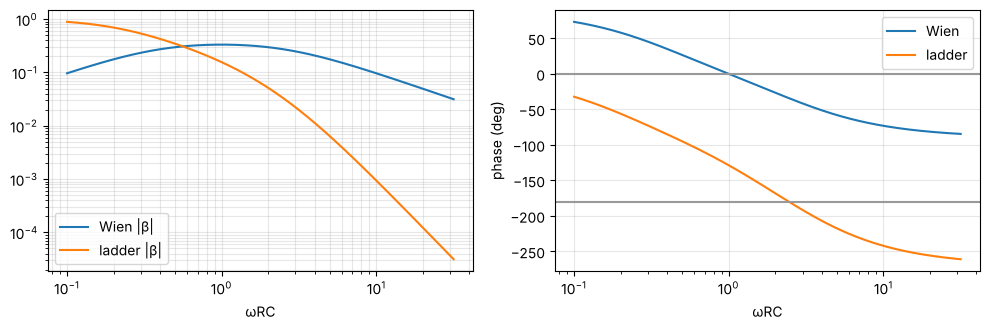

Wien at x = 1: 0.3333-0.0009j; ladder at x = sqrt(6): -0.03448-0.00000j


In [2]:
x = np.logspace(-1, 1.5, 600)
wien = 1 / (3 + 1j * (x - 1 / x))
lad = 1 / ((1j * x) ** 3 + 5 * (1j * x) ** 2 + 6 * (1j * x) + 1)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].semilogx(x, np.abs(wien), label='Wien |β|'); ax[0].semilogx(x, np.abs(lad), label='ladder |β|')
ax[0].set_yscale('log'); ax[0].legend(); ax[0].grid(True, which='both', alpha=0.3); ax[0].set_xlabel('ωRC')
ax[1].semilogx(x, np.degrees(np.angle(wien)), label='Wien'); ax[1].semilogx(x, np.degrees(np.unwrap(np.angle(lad))), label='ladder')
ax[1].axhline(0, color='0.6'); ax[1].axhline(-180, color='0.6'); ax[1].legend(); ax[1].grid(True, alpha=0.3); ax[1].set_xlabel('ωRC'); ax[1].set_ylabel('phase (deg)')
plt.tight_layout(); plt.show()
print(f"Wien at x = 1: {wien[np.argmin(abs(x - 1))]:.4f}; ladder at x = sqrt(6): {1 / ((1j * 6 ** 0.5) ** 3 + 5 * (1j * 6 ** 0.5) ** 2 + 6j * 6 ** 0.5 + 1):.5f}")

## Part 2 · A Wien-bridge oscillator from noise to steady state (the chapter's guided exercise)

$R$ = 10 kΩ, $C$ = 10 nF, amplifier $v_{out} = \tanh(3.3\,v_p)$. **Predict first:** exactly 1592 Hz? What amplitude at the bridge output?

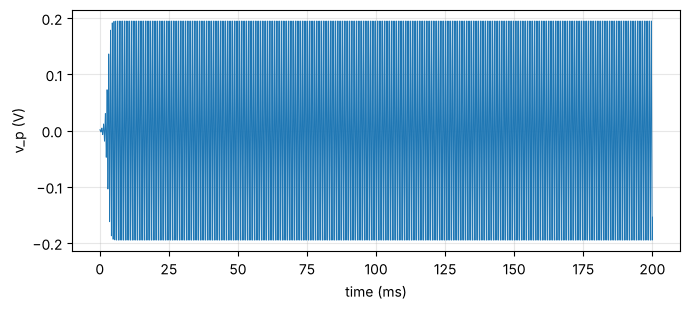

frequency 1583.7 Hz (-0.49% from 1/(2 pi RC)); amplitude at p 0.1949 V; describing function 0.1948 V


In [3]:
R, C, G = 10e3, 10e-9, 3.3
def rhs(t, x):
    vc1, vp = x
    i = (math.tanh(G * vp) - vc1 - vp) / R
    return [i / C, (i - vp / R) / C]
sol = solve_ivp(rhs, (0, 0.2), [0, 1e-3], max_step=2e-6, rtol=1e-10, atol=1e-12)
t, vp = sol.t, sol.y[1]
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(t * 1e3, vp, lw=0.6); ax.set_xlabel('time (ms)'); ax.set_ylabel('v_p (V)'); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()
late = t > 0.15
k = np.where((vp[:-1] < 0) & (vp[1:] >= 0) & late[:-1])[0]
tz = t[k] - vp[k] * (t[k + 1] - t[k]) / (vp[k + 1] - vp[k])
f = 1 / np.mean(np.diff(tz))
def N(a):
    return quad(lambda th: math.tanh(G * a * math.sin(th)) * math.sin(th), 0, TP)[0] / (math.pi * a)
a_df = brentq(lambda a: N(a) - 3, 1e-3, 10)
print(f"frequency {f:.1f} Hz ({100 * (f * TP * R * C - 1):+.2f}% from 1/(2 pi RC)); amplitude at p {vp[late].max():.4f} V; describing function {a_df:.4f} V")

## Part 3 · The Colpitts oscillator's poles

$L$ = 1 µH, $C_1 = C_2$ = 1 nF, $R$ = 1 kΩ. The rightmost natural frequency crosses the imaginary axis at $g_mR = C_2/C_1 = 1$.

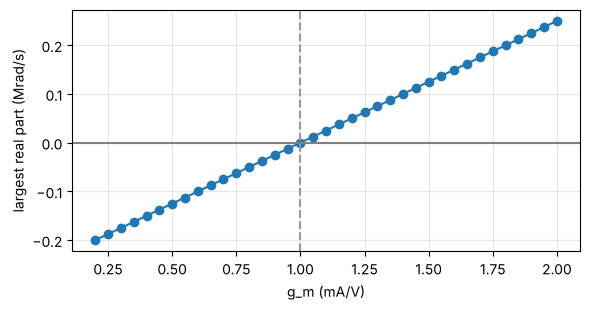

critical g_m = 1.0000 mA/V at 7.1176 MHz


In [4]:
def eigs(gm, L=1e-6, C1=1e-9, C2=1e-9, R=1e3):
    Cm = np.diag([C1, C2, L]); G_ = np.array([[1 / R, gm, 1.0], [0, 0, -1.0], [-1.0, 1.0, 0]])
    return eigvals(-G_, Cm)
gms = np.linspace(0.2e-3, 2e-3, 37)
re = [np.max(eigs(g).real) for g in gms]
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(gms * 1e3, np.array(re) / 1e6, 'o-'); ax.axhline(0, color='0.5'); ax.axvline(1.0, color='0.6', ls='--')
ax.set_xlabel('g_m (mA/V)'); ax.set_ylabel('largest real part (Mrad/s)'); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()
gc = brentq(lambda g: np.max(eigs(g).real), 1e-4, 1e-2)
e = eigs(gc); print(f"critical g_m = {gc * 1e3:.4f} mA/V at {abs(e[np.argmax(e.real)].imag) / TP / 1e6:.4f} MHz")

## Part 4 · A crystal's reactance and pulling

Example 12-09.5's crystal: $f_s$ = 10 MHz, $C_m$ = 25 fF, $R_m$ = 20 Ω, $C_0$ = 5 pF.

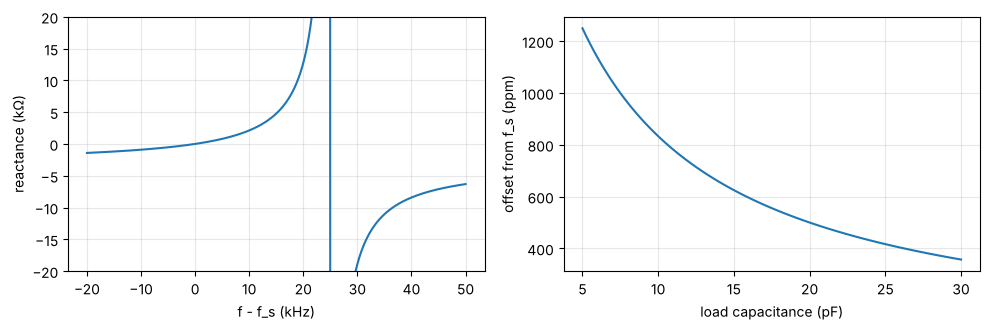

In [5]:
fs, Cm, Rm, C0 = 10e6, 25e-15, 20.0, 5e-12
Lm = 1 / ((TP * fs) ** 2 * Cm)
f = np.linspace(fs - 20e3, fs + 50e3, 4000)
s = 1j * TP * f
Z = 1 / (1 / (Rm + s * Lm + 1 / (s * Cm)) + s * C0)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot((f - fs) / 1e3, Z.imag / 1e3); ax[0].set_ylim(-20, 20); ax[0].grid(True, alpha=0.3)
ax[0].set_xlabel('f - f_s (kHz)'); ax[0].set_ylabel('reactance (kΩ)')
CL = np.linspace(5e-12, 30e-12, 100)
ax[1].plot(CL * 1e12, 1e6 * (np.sqrt(1 + Cm / (C0 + CL)) - 1)); ax[1].grid(True, alpha=0.3)
ax[1].set_xlabel('load capacitance (pF)'); ax[1].set_ylabel('offset from f_s (ppm)')
plt.tight_layout(); plt.show()